# Perbandingan Model Klasifikasi Citra Tipat Upakara Bali
**MobileNetV2 vs EfficientNetB0 vs ResNet50**

Notebook ini mengadaptasi alur dari notebook MobileNetV2 yang diberikan: validasi gambar, pengecualian kelas Tipat Galeng, resize, pembagian data, augmentasi hanya pada training, transfer learning, fine-tuning, dan evaluasi.

Ketiga arsitektur menggunakan **pembagian train/validation/test yang sama**, ukuran citra yang sama, augmentasi yang sama, classifier head yang sama, serta prosedur training/evaluasi yang setara. Fungsi preprocessing mengikuti kebutuhan masing-masing arsitektur.

> Jalankan seluruh notebook dari atas ke bawah. Hasil metrik tidak diisi sebelumnya; semuanya dihitung dari proses training dan test set.

## 1. Konfigurasi dan import

In [1]:
import sys
import os

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nCurrent directory:")
print(os.getcwd())

Python executable:
c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\tipat_env\Scripts\python.exe

Python version:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]

Current directory:
c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING


In [2]:
from pathlib import Path
import random, json, time, gc, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageFile, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Sesuaikan jika folder dataset berada di lokasi berbeda.
SOURCE_DIR = Path(r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat")
OUTPUT_DIR = SOURCE_DIR.parent / "Tipat_Compare_Preprocessed"
MODEL_DIR = SOURCE_DIR.parent / "Tipat_Compare_Models"
RESULT_DIR = SOURCE_DIR.parent / "Hasil_Perbandingan_Tipat"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42
MIN_IMAGES_PER_CLASS = 7
EXCLUDED_CLASSES = {"Tipat Galeng"}
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

tf.keras.utils.set_random_seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False
for folder in [MODEL_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Dataset:", SOURCE_DIR)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.15.1
Dataset: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat
GPU: []


## 2. Validasi gambar dan pemeriksaan jumlah data per kelas

In [3]:
if not SOURCE_DIR.exists():
    raise FileNotFoundError(f"Folder dataset tidak ditemukan: {SOURCE_DIR}")

dataset = {}
invalid_count = 0

for class_dir in sorted(SOURCE_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    if class_dir.name.strip().casefold() in {x.casefold() for x in EXCLUDED_CLASSES}:
        print(f"[DIKECUALIKAN] {class_dir.name}")
        continue

    valid_paths = []
    for path in sorted(class_dir.iterdir()):
        if not path.is_file() or path.suffix.lower() not in VALID_EXTENSIONS:
            continue
        try:
            with Image.open(path) as img:
                img.verify()
            with Image.open(path) as img:
                img.convert("RGB")
            valid_paths.append(path)
        except (OSError, ValueError, UnidentifiedImageError) as exc:
            invalid_count += 1
            print(f"[GAMBAR TIDAK VALID] {path.name}: {exc}")

    if valid_paths:
        dataset[class_dir.name] = valid_paths

if len(dataset) < 2:
    raise ValueError("Diperlukan minimal dua kelas dengan gambar valid.")

class_counts = {name: len(paths) for name, paths in dataset.items()}
print("Jumlah gambar valid per kelas:")
for name, count in class_counts.items():
    print(f"{name}: {count}")
print("Total gambar valid:", sum(class_counts.values()))
print("Gambar tidak valid:", invalid_count)

small_classes = {k:v for k,v in class_counts.items() if v < MIN_IMAGES_PER_CLASS}
if small_classes:
    raise ValueError(
        f"Kelas berikut memiliki kurang dari {MIN_IMAGES_PER_CLASS} gambar: {small_classes}. "
        "Tambahkan foto asli atau evaluasi kembali kelayakan kelas tersebut sebelum split."
    )

[DIKECUALIKAN] Tipat Galeng
Jumlah gambar valid per kelas:
Tipat Dampulan: 74
Tipat Gatep: 51
Tipat Gong: 67
Tipat Kukur: 51
Tipat Lepet: 53
Tipat Nasi: 51
Tipat Pengambean: 55
Tipat Sari: 59
Tipat Sirikan: 75
Tipat Taluh: 51
Total gambar valid: 587
Gambar tidak valid: 0


## 3. Pembagian dataset yang sama untuk semua model (70:15:15)
Pembagian dilakukan per kelas agar setiap kelas terwakili pada train, validation, dan test. Hasil split disimpan ke disk dan dipakai ulang oleh ketiga model.

In [4]:
import shutil

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_items, val_items, test_items = [], [], []

for class_name, paths in sorted(dataset.items()):
    paths = list(paths)
    train_paths, temp_paths = train_test_split(
        paths, test_size=0.30, random_state=SEED, shuffle=True
    )
    val_paths, test_paths = train_test_split(
        temp_paths, test_size=0.50, random_state=SEED, shuffle=True
    )
    train_items.extend((p, class_name) for p in train_paths)
    val_items.extend((p, class_name) for p in val_paths)
    test_items.extend((p, class_name) for p in test_paths)

def save_split(items, split_name):
    for source_path, class_name in items:
        dest_dir = OUTPUT_DIR / split_name / class_name
        dest_dir.mkdir(parents=True, exist_ok=True)
        dest_path = dest_dir / f"{source_path.stem}.jpg"
        with Image.open(source_path) as img:
            img.convert("RGB").resize(
                IMAGE_SIZE, Image.Resampling.LANCZOS
            ).save(dest_path, "JPEG", quality=95)

for split_name, items in [
    ("train", train_items), ("validation", val_items), ("test", test_items)
]:
    save_split(items, split_name)

total = len(train_items) + len(val_items) + len(test_items)
print(f"Train      : {len(train_items)} ({len(train_items)/total:.1%})")
print(f"Validation : {len(val_items)} ({len(val_items)/total:.1%})")
print(f"Test       : {len(test_items)} ({len(test_items)/total:.1%})")
print("Lokasi split:", OUTPUT_DIR)

Train      : 405 (69.0%)
Validation : 89 (15.2%)
Test       : 93 (15.8%)
Lokasi split: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Compare_Preprocessed


## 4. Dataset TensorFlow dan augmentasi
Augmentasi hanya diterapkan pada data training. Validation dan test tidak diaugmentasi.

In [5]:
TRAIN_DIR = OUTPUT_DIR / "train"
VAL_DIR = OUTPUT_DIR / "validation"
TEST_DIR = OUTPUT_DIR / "test"
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
if class_names != val_ds.class_names or class_names != test_ds.class_names:
    raise ValueError("Urutan kelas tidak konsisten antar-split.")

with open(RESULT_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="reflect", seed=SEED+1),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.05, 0.10), width_factor=(-0.05, 0.10),
        fill_mode="reflect", seed=SEED+2
    ),
    tf.keras.layers.RandomFlip("horizontal", seed=SEED+3)
], name="data_augmentation")

print("Kelas:", class_names)
print("Jumlah kelas:", num_classes)

Found 405 files belonging to 10 classes.
Found 89 files belonging to 10 classes.
Found 93 files belonging to 10 classes.

Kelas: ['Tipat Dampulan', 'Tipat Gatep', 'Tipat Gong', 'Tipat Kukur', 'Tipat Lepet', 'Tipat Nasi', 'Tipat Pengambean', 'Tipat Sari', 'Tipat Sirikan', 'Tipat Taluh']
Jumlah kelas: 10


## 5. Fungsi preprocessing khusus setiap arsitektur
MobileNetV2 menggunakan skala piksel sekitar [-1, 1], ResNet50 menggunakan preprocessing gaya Caffe (BGR dan mean subtraction), sedangkan EfficientNetB0 pada TensorFlow/Keras menyertakan rescaling di dalam model sehingga fungsi `preprocess_input`-nya pada umumnya pass-through.

In [6]:
PREPROCESSORS = {
    "MobileNetV2": tf.keras.applications.mobilenet_v2.preprocess_input,
    "EfficientNetB0": tf.keras.applications.efficientnet.preprocess_input,
    "ResNet50": tf.keras.applications.resnet50.preprocess_input,
}

def make_datasets(preprocess_fn):
    def prepare_train(images, labels):
        images = data_augmentation(images, training=True)
        return preprocess_fn(images), labels

    def prepare_eval(images, labels):
        return preprocess_fn(images), labels

    train_ready = train_ds.map(
        prepare_train, num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)
    val_ready = val_ds.map(
        prepare_eval, num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)
    test_ready = test_ds.map(
        prepare_eval, num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)
    return train_ready, val_ready, test_ready

## 6. Definisi model dan strategi training
Setiap model memakai ImageNet pretrained weights, Global Average Pooling, Dropout 0.30, dan Dense softmax. Tahap pertama membekukan backbone (transfer learning), kemudian fine-tuning 30 layer terakhir yang bukan BatchNormalization.

In [7]:
def create_backbone(model_name):
    constructors = {
        "MobileNetV2": tf.keras.applications.MobileNetV2,
        "EfficientNetB0": tf.keras.applications.EfficientNetB0,
        "ResNet50": tf.keras.applications.ResNet50,
    }
    backbone = constructors[model_name](
        input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
        include_top=False,
        weights="imagenet"
    )
    return backbone

def build_model(model_name):
    backbone = create_backbone(model_name)
    backbone.trainable = False

    inputs = tf.keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
    x = backbone(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name=f"Tipat_{model_name}")
    return model, backbone

def callbacks_for(path, patience):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            str(path), monitor="val_loss", save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience,
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2,
            min_lr=1e-7, verbose=1
        )
    ]

## 7. Jalankan eksperimen ketiga model
Pengaturan epoch maksimum dibuat sama untuk ketiga arsitektur. Early stopping dapat menghentikan training lebih awal berdasarkan validation loss.

In [8]:
MODEL_NAMES = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
MAX_EPOCHS_TRANSFER = 20
MAX_EPOCHS_FINE = 15
FINE_TUNE_LAST_N = 30

histories = {}
trained_model_paths = {}
training_summary = []

for model_name in MODEL_NAMES:
    print("\n" + "="*70)
    print("MULAI EKSPERIMEN:", model_name)
    print("="*70)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    train_ready, val_ready, test_ready = make_datasets(PREPROCESSORS[model_name])
    model, backbone = build_model(model_name)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    transfer_path = MODEL_DIR / f"{model_name.lower()}_transfer.keras"
    fine_path = MODEL_DIR / f"{model_name.lower()}_fine_tuned.keras"

    start_time = time.time()
    history_transfer = model.fit(
        train_ready, validation_data=val_ready,
        epochs=MAX_EPOCHS_TRANSFER,
        callbacks=callbacks_for(transfer_path, patience=5),
        verbose=1
    )

    model = tf.keras.models.load_model(transfer_path)
    backbone = model.get_layer(backbone.name)

    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = False
    for layer in backbone.layers[-FINE_TUNE_LAST_N:]:
        if not isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = True

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history_fine = model.fit(
        train_ready, validation_data=val_ready,
        epochs=MAX_EPOCHS_FINE,
        callbacks=callbacks_for(fine_path, patience=4),
        verbose=1
    )

    elapsed = time.time() - start_time
    best_model = tf.keras.models.load_model(fine_path)

    histories[model_name] = {
        "transfer": history_transfer.history,
        "fine_tuning": history_fine.history
    }
    trained_model_paths[model_name] = str(fine_path)
    training_summary.append({
        "Model": model_name,
        "Training Time (seconds)": round(elapsed, 2),
        "Total Parameters": int(best_model.count_params()),
        "Trainable Parameters": int(sum(
            np.prod(v.shape) for v in best_model.trainable_weights
        ))
    })

    print(f"{model_name} selesai dalam {elapsed/60:.2f} menit.")
    del model, backbone, best_model, train_ready, val_ready, test_ready
    gc.collect()

training_summary_df = pd.DataFrame(training_summary)
display(training_summary_df)
training_summary_df.to_csv(RESULT_DIR / "training_summary.csv", index=False)


MULAI EKSPERIMEN: MobileNetV2

Epoch 1/20


26/26 [==============================] - ETA: 0s - loss: 2.2649 - accuracy: 0.2420
Epoch 1: val_loss improved from inf to 1.36099, saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Compare_Models\mobilenetv2_transfer.keras
26/26 [==============================] - 9s 206ms/step - loss: 2.2649 - accuracy: 0.2420 - val_loss: 1.3610 - val_accuracy: 0.6180 - lr: 0.0010
Epoch 2/20
25/26 [===========================>..] - ETA: 0s - loss: 1.1317 - accuracy: 0.6450
Epoch 2: val_loss improved from 1.36099 to 0.87219, saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Compare_Models\mobilenetv2_transfer.keras
26/26 [==============================] - 4s 157ms/step - loss: 1.1269 - accuracy: 0.6469 - val_loss: 0.8722 - val_accuracy: 0.7865 - lr: 0.0010
Epoch 3/20
25/26 [===========================>..] - ETA: 0s - loss: 0.7510 - accuracy: 0.7925
Epoch 3: val_loss improved from 0.87219 to 0.65308, saving

,Model,Training Time (seconds),Total Parameters,Trainable Parameters
0,MobileNetV2,123.22,2270794,1523530
1,EfficientNetB0,253.06,4062381,1496170
2,ResNet50,489.89,23608202,14449162


## 8. Grafik riwayat training
Grafik ditampilkan terpisah untuk setiap model dan tahap.

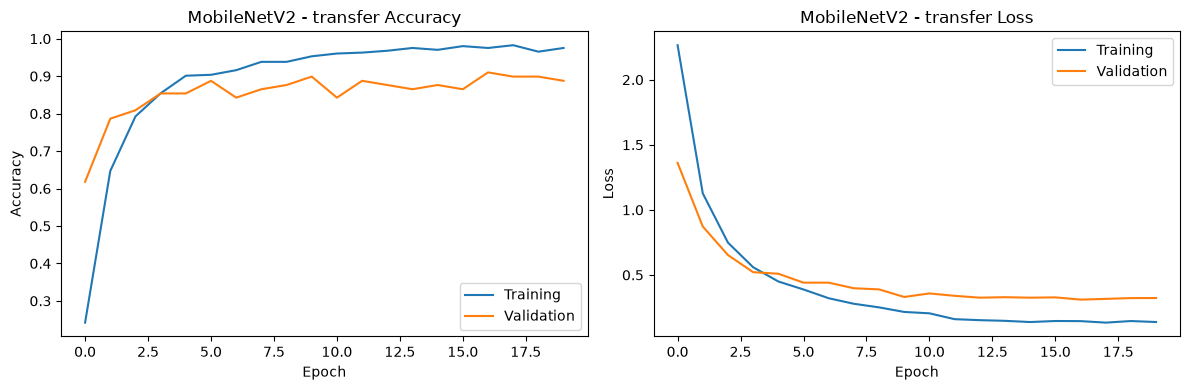

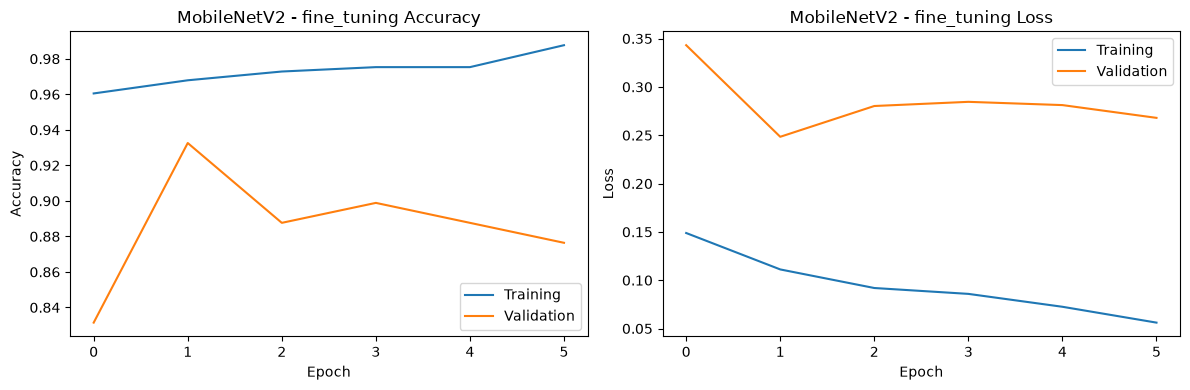

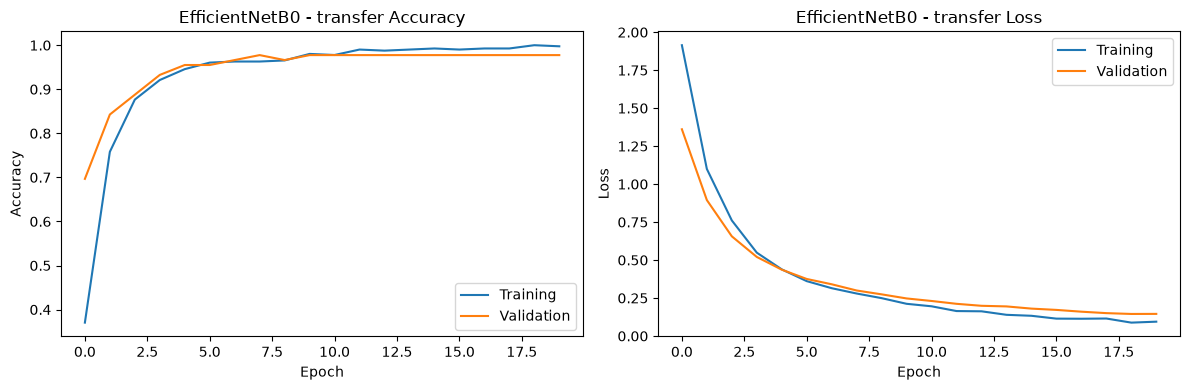

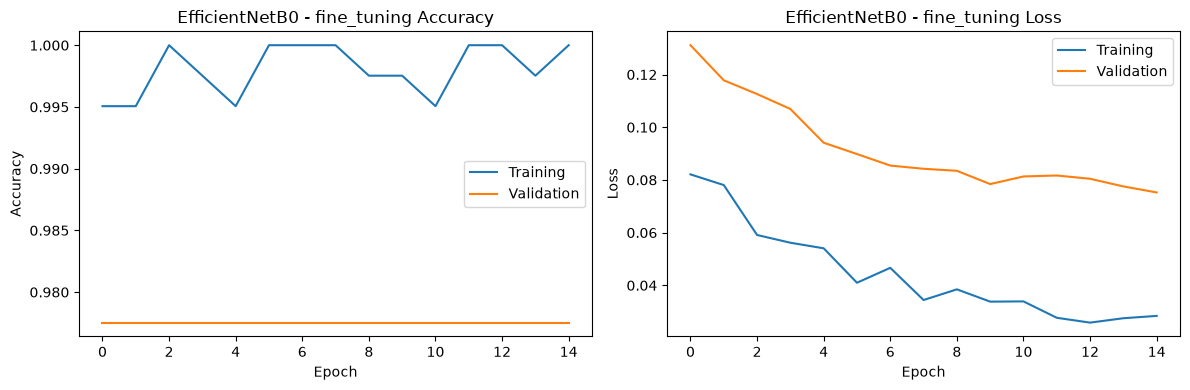

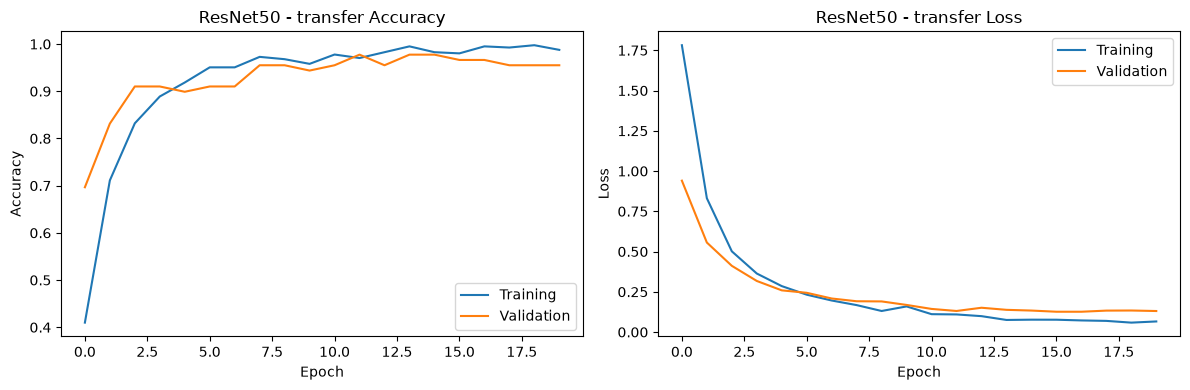

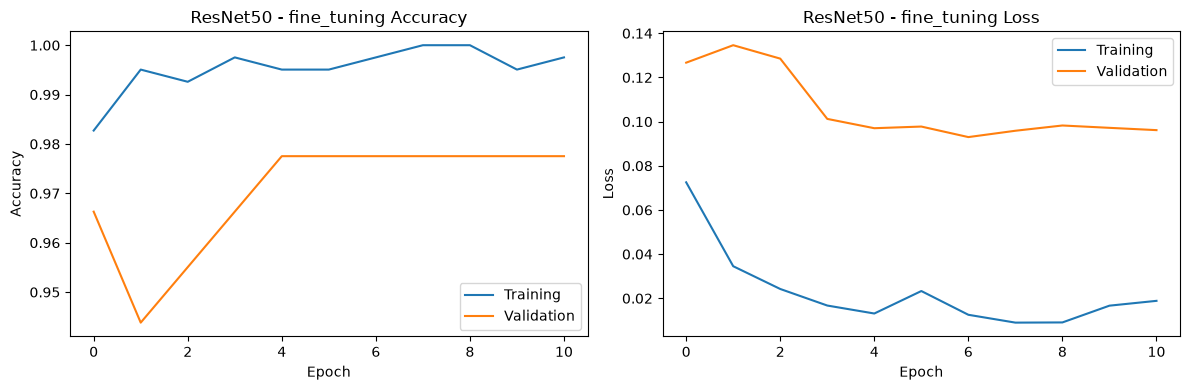

In [9]:
def plot_one_history(history_dict, model_name, stage):
    h = history_dict[stage]
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(h.get("accuracy", []), label="Training")
    plt.plot(h.get("val_accuracy", []), label="Validation")
    plt.title(f"{model_name} - {stage} Accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(h.get("loss", []), label="Training")
    plt.plot(h.get("val_loss", []), label="Validation")
    plt.title(f"{model_name} - {stage} Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
    plt.tight_layout()
    plt.show()

for name in MODEL_NAMES:
    plot_one_history(histories[name], name, "transfer")
    plot_one_history(histories[name], name, "fine_tuning")

## 9. Evaluasi semua model pada test set yang sama
Test set tidak digunakan untuk memilih model, epoch, atau hyperparameter. Metrik utama mencakup Accuracy, Precision Macro, Recall Macro, F1 Macro, dan F1 Weighted.


Evaluasi: MobileNetV2
6/6 [==============================] - 1s 100ms/step
                  precision    recall  f1-score   support

  Tipat Dampulan     1.0000    0.8333    0.9091        12
     Tipat Gatep     0.8889    1.0000    0.9412         8
      Tipat Gong     0.8182    0.8182    0.8182        11
     Tipat Kukur     1.0000    1.0000    1.0000         8
     Tipat Lepet     1.0000    1.0000    1.0000         8
      Tipat Nasi     1.0000    1.0000    1.0000         8
Tipat Pengambean     1.0000    1.0000    1.0000         9
      Tipat Sari     1.0000    1.0000    1.0000         9
   Tipat Sirikan     0.7857    0.9167    0.8462        12
     Tipat Taluh     1.0000    0.8750    0.9333         8

        accuracy                         0.9355        93
       macro avg     0.9493    0.9443    0.9448        93
    weighted avg     0.9413    0.9355    0.9361        93



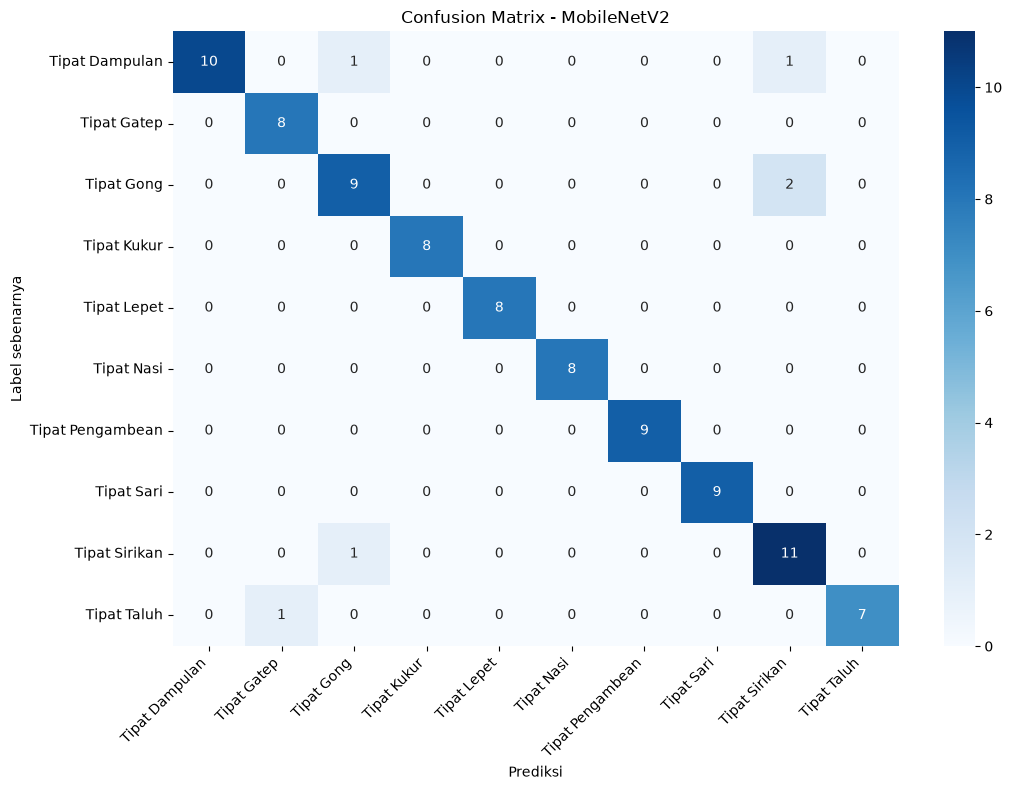


Evaluasi: EfficientNetB0
6/6 [==============================] - 2s 144ms/step
                  precision    recall  f1-score   support

  Tipat Dampulan     1.0000    0.9167    0.9565        12
     Tipat Gatep     1.0000    1.0000    1.0000         8
      Tipat Gong     0.9000    0.8182    0.8571        11
     Tipat Kukur     0.8889    1.0000    0.9412         8
     Tipat Lepet     1.0000    1.0000    1.0000         8
      Tipat Nasi     1.0000    1.0000    1.0000         8
Tipat Pengambean     1.0000    1.0000    1.0000         9
      Tipat Sari     1.0000    1.0000    1.0000         9
   Tipat Sirikan     0.8462    0.9167    0.8800        12
     Tipat Taluh     1.0000    1.0000    1.0000         8

        accuracy                         0.9570        93
       macro avg     0.9635    0.9652    0.9635        93
    weighted avg     0.9588    0.9570    0.9569        93



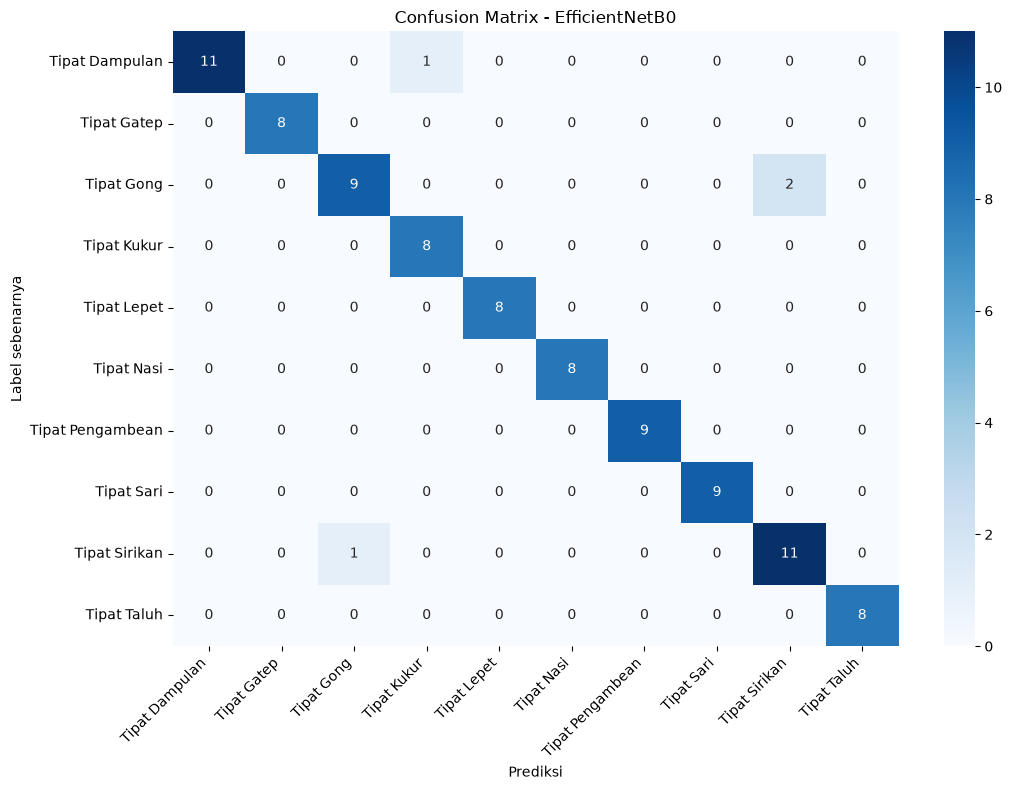


Evaluasi: ResNet50
6/6 [==============================] - 3s 375ms/step
                  precision    recall  f1-score   support

  Tipat Dampulan     0.8462    0.9167    0.8800        12
     Tipat Gatep     1.0000    1.0000    1.0000         8
      Tipat Gong     0.8333    0.9091    0.8696        11
     Tipat Kukur     1.0000    1.0000    1.0000         8
     Tipat Lepet     1.0000    1.0000    1.0000         8
      Tipat Nasi     0.8889    1.0000    0.9412         8
Tipat Pengambean     1.0000    0.8889    0.9412         9
      Tipat Sari     1.0000    1.0000    1.0000         9
   Tipat Sirikan     1.0000    0.8333    0.9091        12
     Tipat Taluh     1.0000    1.0000    1.0000         8

        accuracy                         0.9462        93
       macro avg     0.9568    0.9548    0.9541        93
    weighted avg     0.9509    0.9462    0.9466        93



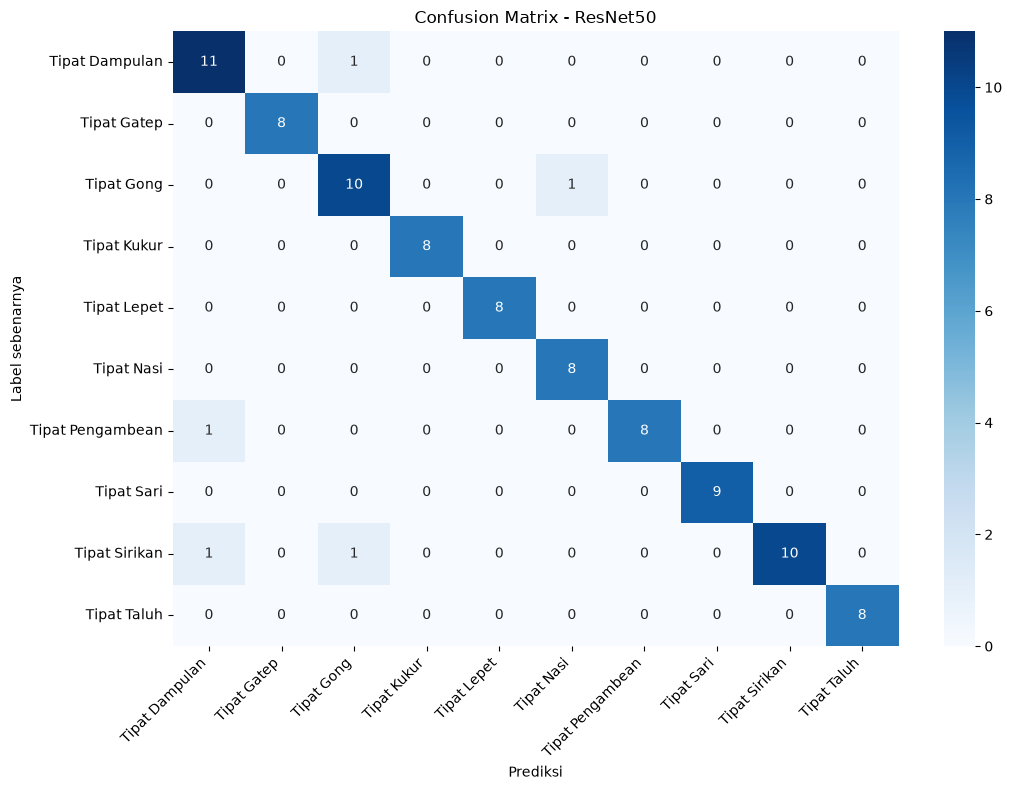

,Model,Training Time (seconds),Total Parameters,Trainable Parameters,Test Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0,MobileNetV2,123.22,2270794,1523530,0.1853,0.9355,0.9493,0.9443,0.9448,0.9361
1,EfficientNetB0,253.06,4062381,1496170,0.1626,0.9570,0.9635,0.9652,0.9635,0.9569
2,ResNet50,489.89,23608202,14449162,0.1342,0.9462,0.9568,0.9548,0.9541,0.9466


Hasil disimpan di: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Hasil_Perbandingan_Tipat


In [10]:
evaluation_rows = []
all_reports = {}
all_predictions = {}

for model_name in MODEL_NAMES:
    print("\nEvaluasi:", model_name)
    tf.keras.backend.clear_session()

    _, _, test_ready = make_datasets(PREPROCESSORS[model_name])
    model = tf.keras.models.load_model(trained_model_paths[model_name])

    test_loss, test_accuracy = model.evaluate(test_ready, verbose=1)
    y_true = np.concatenate([y.numpy() for _, y in test_ready])
    y_prob = model.predict(test_ready, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    report = classification_report(
        y_true, y_pred, labels=np.arange(num_classes),
        target_names=class_names, output_dict=True, zero_division=0
    )
    all_reports[model_name] = report
    all_predictions[model_name] = {
        "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob
    }

    evaluation_rows.append({
        "Model": model_name,
        "Test Loss": float(test_loss),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 Weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    })

    print(classification_report(
        y_true, y_pred, target_names=class_names, zero_division=0, digits=4
    ))

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
    plt.figure(figsize=(11, 8))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Prediksi")
    plt.ylabel("Label sebenarnya")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    del model, test_ready
    gc.collect()

evaluation_df = pd.DataFrame(evaluation_rows)
comparison_df = training_summary_df.merge(evaluation_df, on="Model")
display(comparison_df.round(4))
comparison_df.to_csv(RESULT_DIR / "model_comparison_results.csv", index=False)
print("Hasil disimpan di:", RESULT_DIR)

## 10. Grafik perbandingan metrik

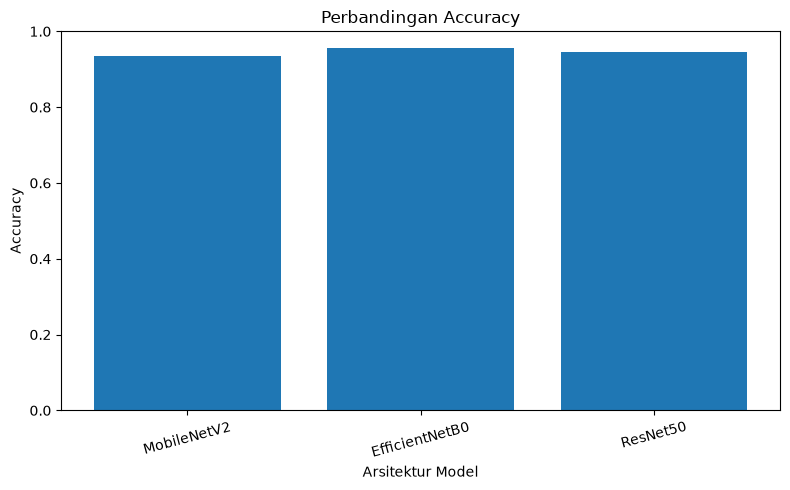

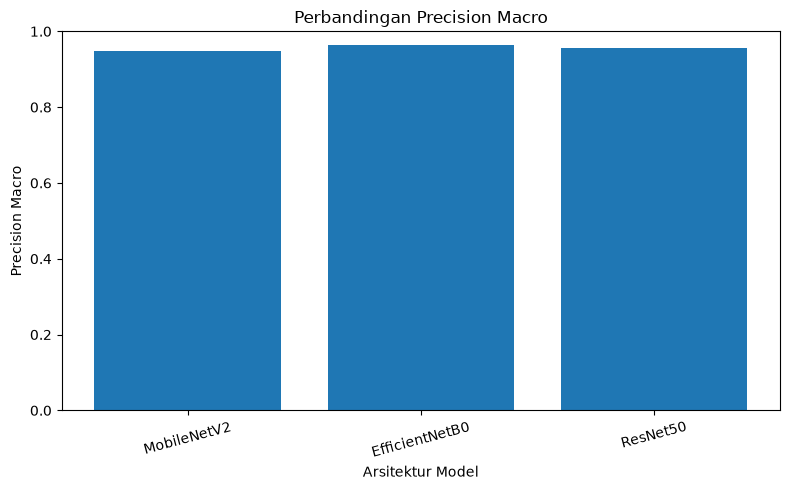

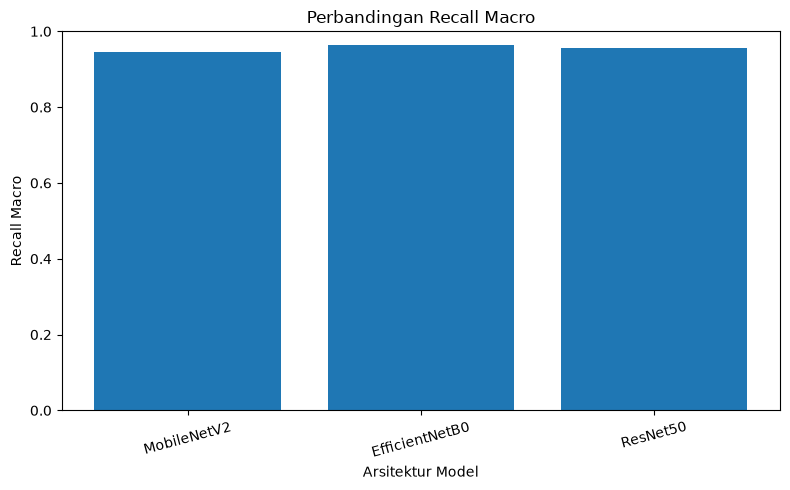

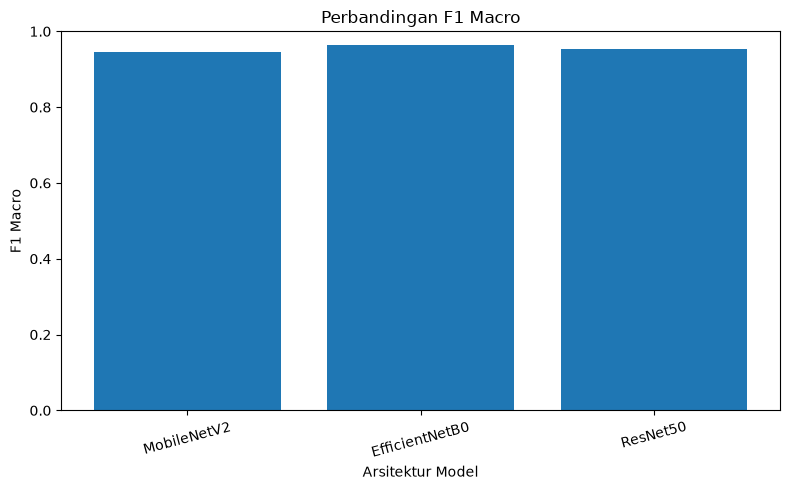

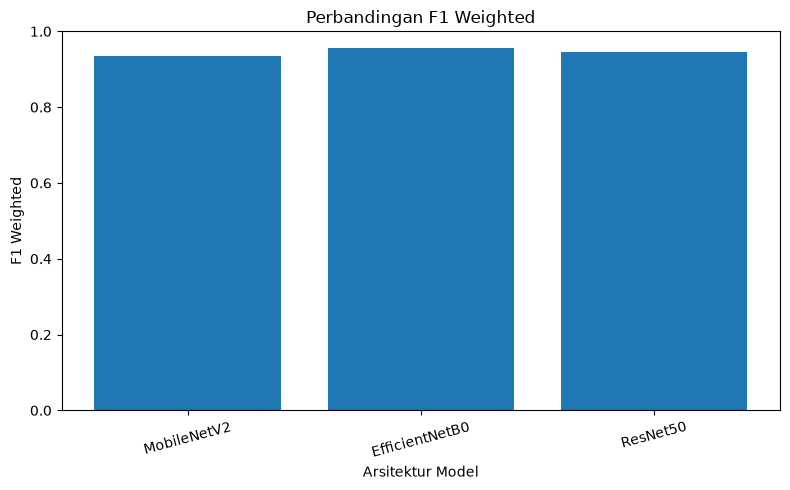

In [11]:
metrics_to_plot = ["Accuracy", "Precision Macro", "Recall Macro", "F1 Macro", "F1 Weighted"]
for metric in metrics_to_plot:
    plt.figure(figsize=(8, 5))
    plt.bar(comparison_df["Model"], comparison_df[metric])
    plt.title(f"Perbandingan {metric}")
    plt.xlabel("Arsitektur Model")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 11. Simpan prediksi test dan ringkasan eksperimen

In [12]:
# Simpan label aktual dan prediksi masing-masing model untuk audit hasil.
prediction_data = {
    "y_true": all_predictions[MODEL_NAMES[0]]["y_true"]
}
for name in MODEL_NAMES:
    prediction_data[f"pred_{name}"] = all_predictions[name]["y_pred"]

pred_df = pd.DataFrame(prediction_data)
pred_df["actual_label"] = [class_names[i] for i in pred_df["y_true"]]
for name in MODEL_NAMES:
    pred_df[f"predicted_label_{name}"] = [
        class_names[i] for i in pred_df[f"pred_{name}"]
    ]
pred_df.to_csv(RESULT_DIR / "test_predictions_all_models.csv", index=False)

print("SELESAI")
print("Perbandingan:", RESULT_DIR / "model_comparison_results.csv")
print("Prediksi:", RESULT_DIR / "test_predictions_all_models.csv")
print("Model tersimpan di:", MODEL_DIR)

SELESAI
Perbandingan: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Hasil_Perbandingan_Tipat\model_comparison_results.csv
Prediksi: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Hasil_Perbandingan_Tipat\test_predictions_all_models.csv
Model tersimpan di: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Compare_Models
